# Task02 for the chapter **Linear Regression**

This task is separated into 7 parts.

The 1st and 2nd parts are about the dataset **Auto**

And we will discuss it in this notebook.

-----
It contains a number of variables for **397 different Autos company**. The
variables are:

- mpg: How far your car can travel for every gallon
- cylinders: The fuel is combusted and power is generated
- displacement: Indicator of the power of the engine
- horsepower: The output of engines or motors
- weight: Weight of a it's cars
- acceleration: Speed of it's car Models
- year: Company founding year
- origin: Classes of each car
- name: Name of the car Company

In [18]:
import pandas as pd
import numpy as np
from matplotlib.pyplot import subplots

In [20]:
auto = pd.read_csv('/content/Auto.csv')

In [5]:
pip install --upgrade ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 62.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 60.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 33.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 42.3 MB/s  0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4118 sha256=59c3c8dbd98ffb07d9901eca53968ab956a8de8faf5938e9525ca66d7ffb4ae7
  Stored in directory: /root/.cache/pip/wheels/7e/16/46/9477f188924292d3bf1fb8fb42844201591abfc19b7ba6d868
Successfully built autograd-gamma
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [ISLP]


In [26]:
print(auto['horsepower'].info())
print(auto['horsepower'].value_counts())
auto['horsepower'] = pd.to_numeric(auto['horsepower'], errors='coerce').fillna(0).astype(int)
print(auto['horsepower'].info())

<class 'pandas.core.series.Series'>
RangeIndex: 397 entries, 0 to 396
Series name: horsepower
Non-Null Count  Dtype 
--------------  ----- 
397 non-null    object
dtypes: object(1)
memory usage: 3.2+ KB
None
horsepower
150    22
90     20
88     19
110    18
100    17
       ..
77      1
132     1
64      1
116     1
82      1
Name: count, Length: 94, dtype: int64
<class 'pandas.core.series.Series'>
RangeIndex: 397 entries, 0 to 396
Series name: horsepower
Non-Null Count  Dtype
--------------  -----
397 non-null    int64
dtypes: int64(1)
memory usage: 3.2 KB
None


In [27]:
'''
  (a) Use the sm.OLS() function to perform a simple linear regression
  with "mpg" as the response and "horsepower" as the predictor. Use
  the summarize() function to print the results
 '''

import statsmodels.api as sm
from ISLP.models import ModelSpec as MS, summarize, poly

design = MS(['horsepower'])
X = design.fit_transform(auto)
y = auto['mpg']
model1 = sm.OLS(y, X)
results1 = model1.fit()
summarize(results1)

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:918: FutureWarning: ModelSpec will move to its own package in ISLP 0.7. `from ISLP.models import ModelSpec` (and the other tools of ISLP.models that build model matrices) will keep working, but other import paths, such as ISLP.models.model_spec, may not, and `intercept` will then default to False. This ModelSpec relies on the default of `intercept`, now True, which adds a column of ones named 'intercept' to the design: only statsmodels' models (OLS, GLM, ...) need it, as glmstar's estimators and most scikit-learn estimators fit the intercept themselves. Pass intercept=True to keep it (e.g. for statsmodels), or intercept=False to drop it.
  return self.fit(X, **fit_params).transform(X)


,coef,std err,t,P>|t|
intercept,38.8792,0.707,55.019,0.0
horsepower,-0.1489,0.006,-23.314,0.0


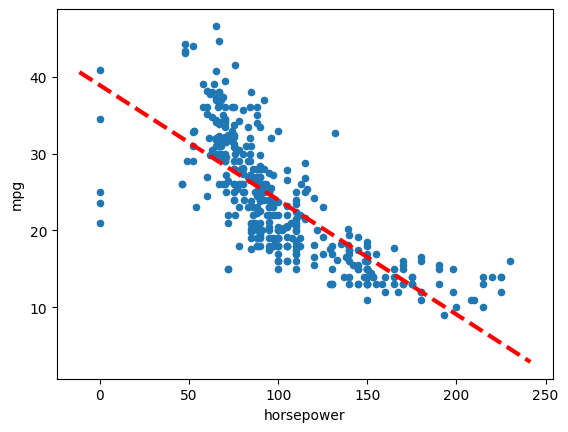

In [28]:
'''
  (b) Plot the response and the predictor in a new set of axes "ax". Use
  the "ax.axline()" method or the "abline()" function defined in the
  lab to display the least squares regression line.
'''

def abline(ax, b, m, *args, **kwargs):
  xlim = ax.get_xlim()
  ylim = [m * xlim[0] + b, m * xlim[1] + b]
  ax.plot(xlim, ylim, *args, **kwargs)

ax = auto.plot.scatter('horsepower', 'mpg')
abline(ax,
        results1.params.iloc[0],
        results1.params.iloc[1],
        'r--',
        linewidth = 3)

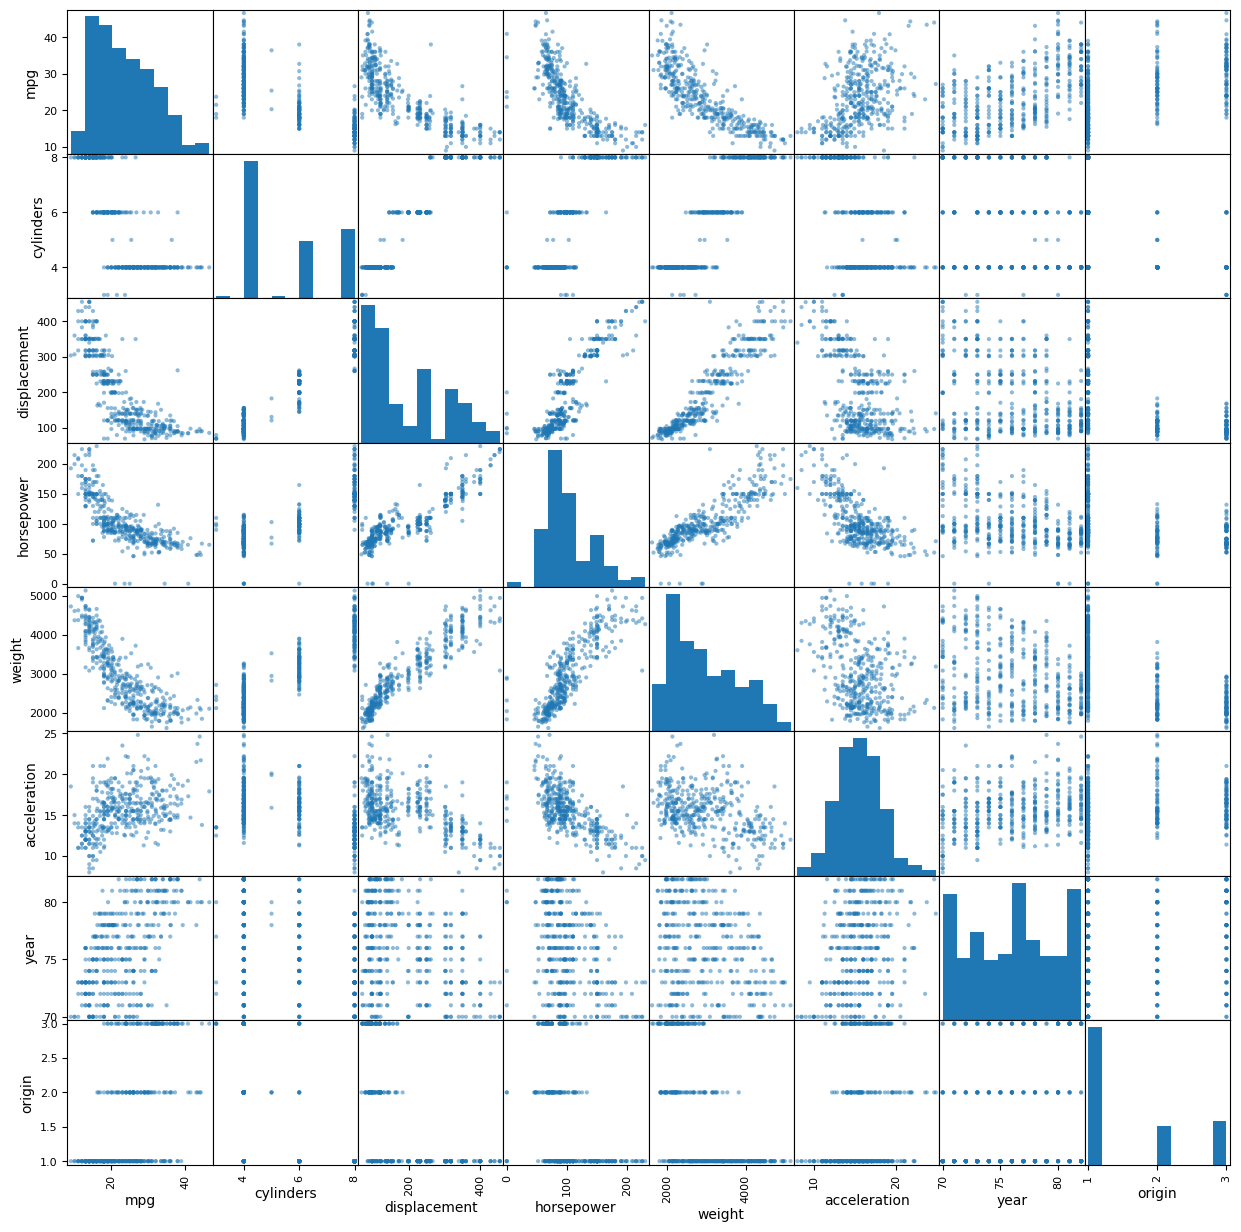

In [29]:
'''
  (a) Produce a scatterplot matrix which includes all of the variables
  in the data set.
'''

import matplotlib.pyplot as plt

pd.plotting.scatter_matrix(auto, figsize = (15, 15))
plt.show()

In [31]:
print(auto.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           397 non-null    float64
 1   cylinders     397 non-null    int64  
 2   displacement  397 non-null    float64
 3   horsepower    397 non-null    int64  
 4   weight        397 non-null    int64  
 5   acceleration  397 non-null    float64
 6   year          397 non-null    int64  
 7   origin        397 non-null    int64  
 8   name          397 non-null    object 
dtypes: float64(3), int64(5), object(1)
memory usage: 28.0+ KB
None


In [32]:
'''
  (b) Compute the matrix of correlations between the variables using
  the DataFrame.corr() method.
'''

correlation_matrix = auto.drop(columns=['name']).corr()
print(correlation_matrix)

                   mpg  cylinders  displacement  horsepower    weight  \
mpg           1.000000  -0.776260     -0.804443   -0.761004 -0.831739   
cylinders    -0.776260   1.000000      0.950920    0.823711  0.897017   
displacement -0.804443   0.950920      1.000000    0.876741  0.933104   
horsepower   -0.761004   0.823711      0.876741    1.000000  0.845483   
weight       -0.831739   0.897017      0.933104    0.845483  1.000000   
acceleration  0.422297  -0.504061     -0.544162   -0.670643 -0.419502   
year          0.581469  -0.346717     -0.369804   -0.405830 -0.307900   
origin        0.563698  -0.564972     -0.610664   -0.427052 -0.581265   

              acceleration      year    origin  
mpg               0.422297  0.581469  0.563698  
cylinders        -0.504061 -0.346717 -0.564972  
displacement     -0.544162 -0.369804 -0.610664  
horsepower       -0.670643 -0.405830 -0.427052  
weight           -0.419502 -0.307900 -0.581265  
acceleration      1.000000  0.282901  0.210084  

In [33]:
'''
  (c) Use the sm.OLS() function to perform a multiple linear regression
  with mpg as the response and all other variables except name as
  the predictors. Use the summarize() function to print the results.
  Comment on the output.
'''

predictors = [col for col in auto.columns if col not in ['mpg', 'name']]
design = MS(predictors)
X = design.fit_transform(auto)
y = auto['mpg']
model2 = sm.OLS(y, X)
results2 = model2.fit()
summarize(results2)

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:918: FutureWarning: ModelSpec will move to its own package in ISLP 0.7. `from ISLP.models import ModelSpec` (and the other tools of ISLP.models that build model matrices) will keep working, but other import paths, such as ISLP.models.model_spec, may not, and `intercept` will then default to False. This ModelSpec relies on the default of `intercept`, now True, which adds a column of ones named 'intercept' to the design: only statsmodels' models (OLS, GLM, ...) need it, as glmstar's estimators and most scikit-learn estimators fit the intercept themselves. Pass intercept=True to keep it (e.g. for statsmodels), or intercept=False to drop it.
  return self.fit(X, **fit_params).transform(X)


,coef,std err,t,P>|t|
intercept,-17.9640,4.449,-4.038,0.000
cylinders,-0.4636,0.322,-1.441,0.150
displacement,0.0200,0.007,2.688,0.007
horsepower,-0.0149,0.011,-1.335,0.183
weight,-0.0066,0.001,-10.544,0.000
acceleration,0.0939,0.091,1.027,0.305
year,0.7574,0.050,15.083,0.000
origin,1.4457,0.277,5.218,0.000
